In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Read the San Diego International Airport observations
df = pd.read_csv(
    "72290023188.csv",
    low_memory=False,
    dtype={"STATION": str}
)

print("Dataset dimensions:", df.shape)
print("Available columns:")
print(df.columns.tolist())

display(df.head())


Dataset dimensions: (14332, 84)
Available columns:
['STATION', 'DATE', 'SOURCE', 'LATITUDE', 'LONGITUDE', 'ELEVATION', 'NAME', 'REPORT_TYPE', 'CALL_SIGN', 'QUALITY_CONTROL', 'WND', 'CIG', 'VIS', 'TMP', 'DEW', 'SLP', 'AA1', 'AA2', 'AA3', 'AB1', 'AD1', 'AE1', 'AH1', 'AH2', 'AH3', 'AH4', 'AH5', 'AH6', 'AI1', 'AI2', 'AI3', 'AI4', 'AI5', 'AI6', 'AT1', 'AT2', 'AT3', 'AU1', 'AU2', 'AW1', 'AW2', 'AW3', 'AX1', 'AX2', 'AX3', 'ED1', 'GA1', 'GA2', 'GA3', 'GD1', 'GD2', 'GD3', 'GD4', 'GE1', 'GF1', 'KA1', 'KA2', 'KB1', 'KB2', 'KB3', 'KC1', 'KC2', 'KD1', 'KD2', 'KE1', 'KG1', 'KG2', 'MA1', 'MD1', 'MF1', 'MG1', 'MH1', 'MK1', 'MW1', 'OC1', 'OD1', 'OE1', 'OE2', 'OE3', 'RH1', 'RH2', 'RH3', 'REM', 'EQD']


,STATION,DATE,SOURCE,LATITUDE,LONGITUDE,ELEVATION,NAME,REPORT_TYPE,CALL_SIGN,QUALITY_CONTROL,...,OC1,OD1,OE1,OE2,OE3,RH1,RH2,RH3,REM,EQD
0,72290023188,2024-01-01T00:00:00,4,32.7336,-117.1831,4.6,"SAN DIEGO INTERNATIONAL AIRPORT, CA US",FM-12,99999,V020,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SYN08072290 32566 60000 10161 20117 30165 4017...,NaN
1,72290023188,2024-01-01T00:17:00,6,32.7336,-117.1831,4.6,"SAN DIEGO INTERNATIONAL AIRPORT, CA US",FM-15,KSAN,V030,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,MET16612/31/23 16:17:03 METAR KSAN 010017Z VRB...,NaN
2,72290023188,2024-01-01T00:51:00,4,32.7336,-117.1831,4.6,"SAN DIEGO INTERNATIONAL AIRPORT, CA US",FM-15,99999,V020,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,MET092METAR KSAN 010051Z 29004KT 10SM FEW030 S...,NaN
3,72290023188,2024-01-01T01:51:00,7,32.7336,-117.1831,4.6,"SAN DIEGO INTERNATIONAL AIRPORT, CA US",FM-15,KSAN,V030,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,MET11212/31/23 17:51:03 METAR KSAN 010151Z 000...,R01 107SM7VIS011
4,72290023188,2024-01-01T02:51:00,7,32.7336,-117.1831,4.6,"SAN DIEGO INTERNATIONAL AIRPORT, CA US",FM-15,KSAN,V030,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,MET19512/31/23 18:51:03 METAR KSAN 010251Z ...,P01 097183APOSLPD01 0ADE726


Non-missing hourly pressures: 72


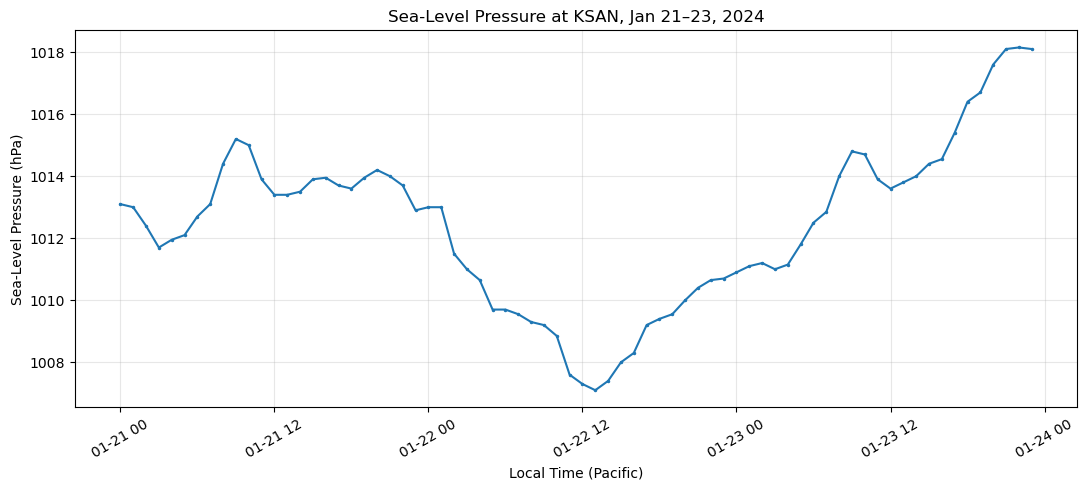

In [2]:
# Convert timestamps from UTC to San Diego local time
df["DATE"] = pd.to_datetime(
    df["DATE"], utc=True, errors="coerce"
)

df["local_time"] = df["DATE"].dt.tz_convert(
    "America/Los_Angeles"
)

# Extract numeric sea-level pressure values
raw_pressure = pd.to_numeric(
    df["SLP"].astype("string").str.split(",").str[0],
    errors="coerce"
)

# Convert tenths of hPa to hPa, removing missing
# and clearly implausible values
df["pressure_hpa"] = (raw_pressure / 10).where(
    raw_pressure.between(8700, 10850)
)

# Select January 21–23, 2024 (local dates)
event = df[
    (df["local_time"] >= "2024-01-21") &
    (df["local_time"] < "2024-01-24")
].copy()

# Average multiple observations within the same hour
hourly = (
    event.set_index("local_time")["pressure_hpa"]
    .resample("1h")
    .mean()
)

print("Non-missing hourly pressures:", hourly.count())

# Create the graph
plt.figure(figsize=(11, 5))
plt.plot(hourly.index, hourly, marker=".", markersize=3)
plt.title("Sea-Level Pressure at KSAN, Jan 21–23, 2024")
plt.xlabel("Local Time (Pacific)")
plt.ylabel("Sea-Level Pressure (hPa)")
plt.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [3]:

# Calculate summary statistics
print("Pressure Statistics (Jan 21–23, 2024)")
print("-------------------------------------")

print(f"Mean pressure: {hourly.mean():.2f} hPa")
print(f"Minimum pressure: {hourly.min():.2f} hPa")
print(f"Maximum pressure: {hourly.max():.2f} hPa")
print(f"Pressure range: {hourly.max() - hourly.min():.2f} hPa")

print("\nTime of minimum pressure:")
print(hourly.idxmin())

print("\nTime of maximum pressure:")
print(hourly.idxmax())


Pressure Statistics (Jan 21–23, 2024)
-------------------------------------
Mean pressure: 1012.42 hPa
Minimum pressure: 1007.10 hPa
Maximum pressure: 1018.15 hPa
Pressure range: 11.05 hPa

Time of minimum pressure:
2024-01-22 13:00:00-08:00

Time of maximum pressure:
2024-01-23 22:00:00-08:00


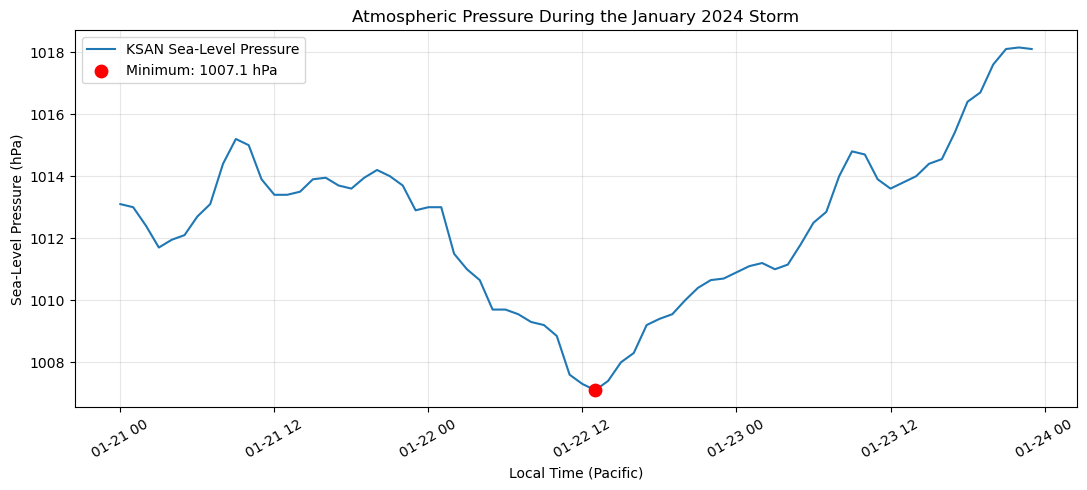

In [4]:

plt.figure(figsize=(11, 5))

plt.plot(
    hourly.index,
    hourly,
    label="KSAN Sea-Level Pressure"
)

# Mark the lowest observed hourly pressure
min_time = hourly.idxmin()
min_value = hourly.min()

plt.scatter(
    min_time,
    min_value,
    color="red",
    s=80,
    zorder=5,
    label=f"Minimum: {min_value:.1f} hPa"
)

plt.title("Atmospheric Pressure During the January 2024 Storm")
plt.xlabel("Local Time (Pacific)")
plt.ylabel("Sea-Level Pressure (hPa)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()

plt.show()


In [ ]:
# Load both station datasets
ksan = pd.read_csv(
    "72290023188.csv", low_memory=False
)

kipl = pd.read_csv(
    "74718503144.csv", low_memory=False
)

# Verify the stations and their coordinates
print("KSAN:")
display(ksan[[
    "NAME", "LATITUDE", "LONGITUDE", "ELEVATION"
]].head(1))

print("KIPL:")
display(kipl[[
    "NAME", "LATITUDE", "LONGITUDE", "ELEVATION"
]].head(1))

# Check whether both have sea-level pressure
# just b/c a station exists in the database doesn't guarantee every meteorological variable is available.
print("KSAN has SLP:", "SLP" in ksan.columns)
print("KIPL has SLP:", "SLP" in kipl.columns)


KSAN:


,NAME,LATITUDE,LONGITUDE,ELEVATION
0,"SAN DIEGO INTERNATIONAL AIRPORT, CA US",32.7336,-117.1831,4.6


KIPL:


,NAME,LATITUDE,LONGITUDE,ELEVATION
0,"IMPERIAL CO AIRPORT, CA US",32.83464,-115.57656,-16.8


KSAN has SLP: True
KIPL has SLP: True


In [10]:

def clean_pressure(df):
    df = df.copy()

    # Convert timestamps
    df["DATE"] = pd.to_datetime(
        df["DATE"], utc=True, errors="coerce"
    )
    df["local_time"] = df["DATE"].dt.tz_convert(
        "America/Los_Angeles"
    )

    # Separate pressure and quality code
    parts = df["SLP"].astype("string").str.split(
        ",", n=1, expand=True
    )

    pressure_raw = pd.to_numeric(
        parts[0], errors="coerce"
    )
    quality = parts[1].str.strip()

    # Keep only measurements passing all QC checks
    valid = (
        pressure_raw.between(8700, 10850) &
        quality.isin(["1", "5"])
    )

    df["pressure_hpa"] = (
        pressure_raw / 10
    ).where(valid)

    # Convert to hourly means
    hourly = (
        df.set_index("local_time")["pressure_hpa"]
        .resample("1h")
        .mean()
    )

    return hourly


ksan_clean = clean_pressure(ksan)
kipl_clean = clean_pressure(kipl)

comparison_clean = pd.concat(
    {
        "KSAN": ksan_clean,
        "KIPL": kipl_clean
    },
    axis=1
).loc["2024-01-21":"2024-01-23"]

comparison_clean = comparison_clean.dropna()

comparison_clean["Difference"] = (
    comparison_clean["KSAN"] -
    comparison_clean["KIPL"]
)

print("Quality-controlled matched hours:",
      len(comparison_clean))

print(comparison_clean.describe())


Quality-controlled matched hours: 72
              KSAN         KIPL  Difference
count         72.0         72.0        72.0
mean   1012.423611  1010.718056    1.705556
std       2.642395     1.720819    1.592181
min         1007.1       1007.2        -2.5
25%        1010.65     1009.675         1.2
50%        1012.95      1010.75         2.1
75%      1013.9625       1011.8         2.7
max        1018.15       1014.8         3.9


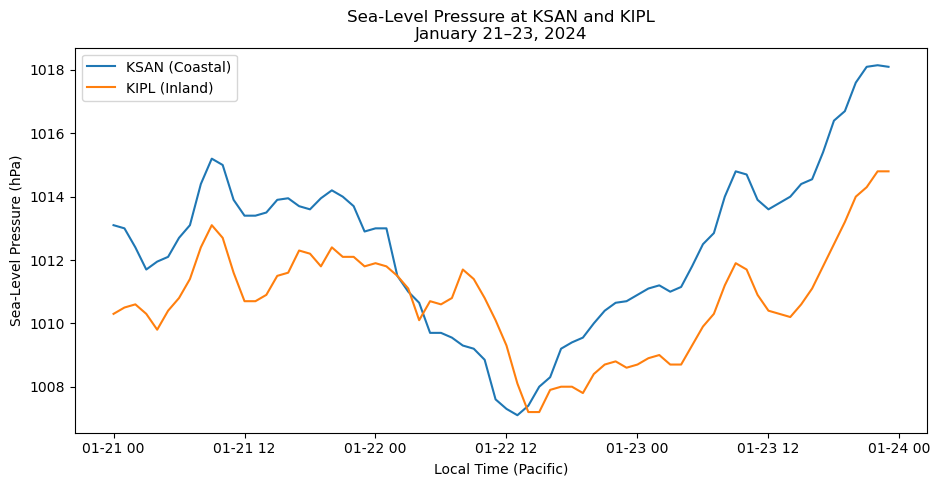

In [13]:
plt.figure(figsize=(11, 5))

plt.plot(
    comparison_clean.index,
    comparison_clean["KSAN"],
    label="KSAN (Coastal)"
)

plt.plot(
    comparison_clean.index,
    comparison_clean["KIPL"],
    label="KIPL (Inland)"
)

plt.title(
    "Sea-Level Pressure at KSAN and KIPL\n"
    "January 21–23, 2024"
)
plt.xlabel("Local Time (Pacific)")
plt.ylabel("Sea-Level Pressure (hPa)")
plt.legend()

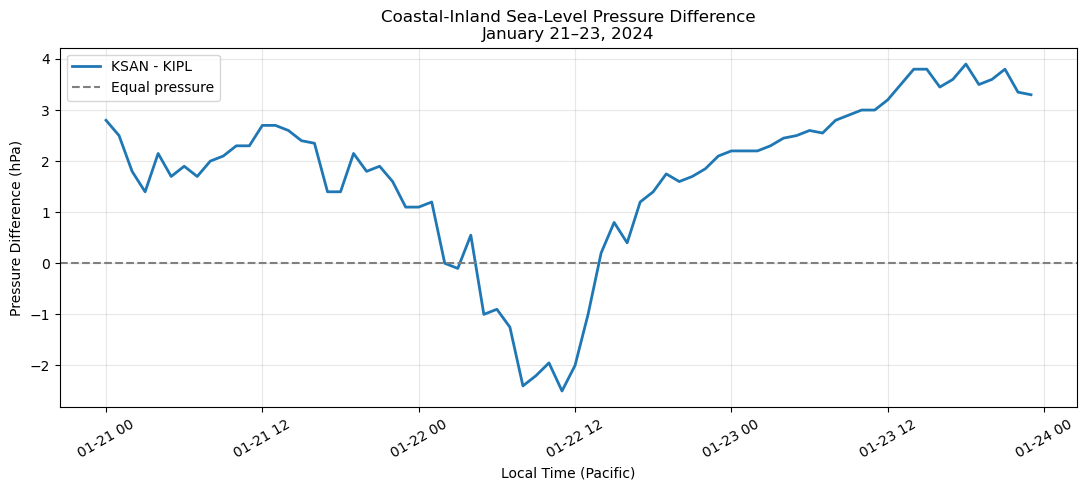

In [11]:
# Use hours with observations at both stations
paired = comparison.dropna().copy()

if paired.empty:
    raise ValueError(
        "No matching pressure observations. "
        "Check KIPL data coverage and SLP values."
    )

# Difference: coastal pressure minus inland pressure
paired["pressure_difference"] = (
    paired["KSAN"] - paired["KIPL"]
)

plt.figure(figsize=(11, 5))

plt.plot(
    paired.index,
    paired["pressure_difference"],
    label="KSAN - KIPL",
    linewidth=2
)

plt.axhline(
    0,
    color="gray",
    linestyle="--",
    label="Equal pressure"
)

plt.title(
    "Coastal-Inland Sea-Level Pressure Difference\n"
    "January 21–23, 2024"
)
plt.xlabel("Local Time (Pacific)")
plt.ylabel("Pressure Difference (hPa)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [14]:
wind_sample = ksan.copy()

wind_sample["DATE"] = pd.to_datetime(
    wind_sample["DATE"], utc=True
)

wind_sample = wind_sample[
    wind_sample["DATE"].between(
        "2024-01-21", "2024-01-24",
        inclusive="left"
    )
]

display(
    wind_sample[["DATE", "NAME", "WND"]].head(15)
)

print("Missing WND values:")
print(wind_sample["WND"].isna().sum())


,DATE,NAME,WND
744,2024-01-21 00:00:00+00:00,"SAN DIEGO INTERNATIONAL AIRPORT, CA US","180,1,N,0026,1"
745,2024-01-21 00:51:00+00:00,"SAN DIEGO INTERNATIONAL AIRPORT, CA US","160,5,N,0015,5"
746,2024-01-21 01:51:00+00:00,"SAN DIEGO INTERNATIONAL AIRPORT, CA US","200,5,N,0031,5"
747,2024-01-21 02:51:00+00:00,"SAN DIEGO INTERNATIONAL AIRPORT, CA US","150,5,N,0021,5"
748,2024-01-21 03:00:00+00:00,"SAN DIEGO INTERNATIONAL AIRPORT, CA US","150,1,N,0021,1"
749,2024-01-21 03:25:00+00:00,"SAN DIEGO INTERNATIONAL AIRPORT, CA US","210,5,N,0031,5"
750,2024-01-21 03:51:00+00:00,"SAN DIEGO INTERNATIONAL AIRPORT, CA US","170,5,N,0036,5"
751,2024-01-21 04:06:00+00:00,"SAN DIEGO INTERNATIONAL AIRPORT, CA US","150,5,N,0031,5"
752,2024-01-21 04:26:00+00:00,"SAN DIEGO INTERNATIONAL AIRPORT, CA US","150,5,N,0026,5"
753,2024-01-21 04:51:00+00:00,"SAN DIEGO INTERNATIONAL AIRPORT, CA US","160,5,N,0036,5"


Missing WND values:
0


In [16]:
def prepare_wind(df):
    data = df[["DATE", "WND"]].copy()

    # Convert timestamps to Pacific local time
    data["local_time"] = pd.to_datetime(
        data["DATE"], utc=True, errors="coerce"
    ).dt.tz_convert("America/Los_Angeles")

    # Split the five components of WND
    parts = data["WND"].astype("string").str.split(
        ",", n=4, expand=True
    )
    parts.columns = [
        "direction", "direction_qc", "wind_type",
        "speed", "speed_qc"
    ]

    direction = pd.to_numeric(
        parts["direction"], errors="coerce"
    )
    speed = pd.to_numeric(
        parts["speed"], errors="coerce"
    )

    # Keep speed values that passed NOAA quality checks
    data["wind_speed_ms"] = (speed / 10).where(
        speed.between(0, 900) &
        parts["speed_qc"].isin(["1", "5"])
    )

    # Only use normal observations with a known,
    # quality-controlled wind direction
    data["wind_direction"] = direction.where(
        direction.between(0, 360) &
        parts["direction_qc"].isin(["1", "5"]) &
        parts["wind_type"].eq("N")
    )

    data["wind_type"] = parts["wind_type"]

    # Filter using LOCAL dates, not UTC dates
    data = data[
        (data["local_time"] >= "2024-01-21") &
        (data["local_time"] < "2024-01-24")
    ].sort_values("local_time")

    return data


ksan_wind = prepare_wind(ksan)

print("Total records:", len(ksan_wind))
print("Valid wind speeds:",
      ksan_wind["wind_speed_ms"].notna().sum())
print("Valid wind directions:",
      ksan_wind["wind_direction"].notna().sum())

print("\nWind observation types:")
print(ksan_wind["wind_type"].value_counts())

display(ksan_wind.head())


Total records: 197
Valid wind speeds: 194
Valid wind directions: 167

Wind observation types:
wind_type
N    169
V     15
C     10
9      3
Name: count, dtype: Int64


,DATE,WND,local_time,wind_speed_ms,wind_direction,wind_type
763,2024-01-21T08:01:00,"180,5,N,0041,5",2024-01-21 00:01:00-08:00,4.1,180,N
764,2024-01-21T08:51:00,"190,5,N,0031,5",2024-01-21 00:51:00-08:00,3.1,190,N
765,2024-01-21T08:57:00,"200,5,N,0031,5",2024-01-21 00:57:00-08:00,3.1,200,N
766,2024-01-21T09:00:00,"190,1,N,0031,1",2024-01-21 01:00:00-08:00,3.1,190,N
767,2024-01-21T09:51:00,"170,5,N,0031,5",2024-01-21 01:51:00-08:00,3.1,170,N


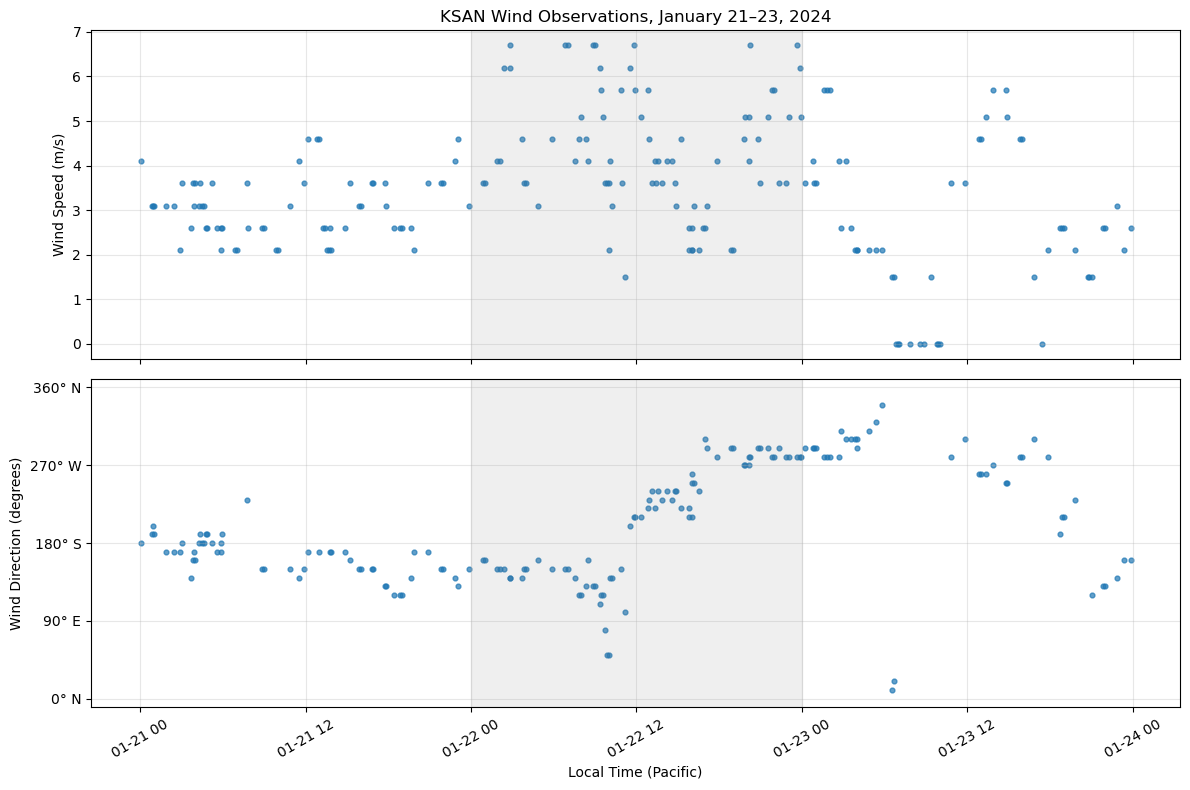

In [21]:
ksan_wind.loc[
    ksan_wind["wind_speed_ms"] == 0,
    "wind_direction"
] = float("nan")

fig, axes = plt.subplots(
    2, 1, figsize=(12, 8), sharex=True
)

# Plot wind speed
axes[0].scatter(
    ksan_wind["local_time"],
    ksan_wind["wind_speed_ms"],
    s=12, alpha=0.7
)

axes[0].set_title(
    "KSAN Wind Observations, January 21–23, 2024"
)
axes[0].set_ylabel("Wind Speed (m/s)")
axes[0].grid(alpha=0.3)

# Plot wind direction
axes[1].scatter(
    ksan_wind["local_time"],
    ksan_wind["wind_direction"],
    s=12, alpha=0.7
)

axes[1].set_ylabel("Wind Direction (degrees)")
axes[1].set_xlabel("Local Time (Pacific)")
axes[1].set_yticks([0, 90, 180, 270, 360])
axes[1].set_yticklabels([
    "0° N", "90° E", "180° S", "270° W", "360° N"
])
axes[1].set_ylim(-10, 370)
axes[1].grid(alpha=0.3)

# Highlight January 22
start = pd.Timestamp(
    "2024-01-22", tz="America/Los_Angeles"
)
end = pd.Timestamp(
    "2024-01-23", tz="America/Los_Angeles"
)

for ax in axes:
    ax.axvspan(
        start, end, color="gray", alpha=0.12
    )

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [22]:
jan22 = ksan_wind[
    (ksan_wind["local_time"] >= "2024-01-22") &
    (ksan_wind["local_time"] < "2024-01-23")
]

print("January 22 Wind Statistics")
print("--------------------------")
print(f"Mean speed: {jan22['wind_speed_ms'].mean():.2f} m/s")
print(f"Maximum speed: {jan22['wind_speed_ms'].max():.2f} m/s")
print(f"Valid wind directions: {jan22['wind_direction'].count()}")

# Distribution of wind observations by quadrant
directions = jan22["wind_direction"].dropna()

print("\nDirection counts:")
print("N:", ((directions >= 315) | (directions < 45)).sum())
print("E:", ((directions >= 45) & (directions < 135)).sum())
print("S:", ((directions >= 135) & (directions < 225)).sum())
print("W:", ((directions >= 225) & (directions < 315)).sum())

January 22 Wind Statistics
--------------------------
Mean speed: 4.33 m/s
Maximum speed: 6.70 m/s
Valid wind directions: 74

Direction counts:
N: 0
E: 12
S: 29
W: 33
